# Milestone 6: STATS19 Exploratory Data Analysis (EDA) & Statistical Profiling
**Project**: Smart Road Accident Hotspot Analysis and Risk Prediction System  
**Database**: PostgreSQL 16 (`road_safety`)  
**Dataset**: UK Department for Transport STATS19 (2021–2025, 513,801 Collisions)  

---

## Overview
This notebook provides the official exploratory data analysis for the project, directly querying relational views in PostgreSQL. Each visualization addresses a specific research question, reports 95% Wilson Score confidence intervals where appropriate, and includes domain insights paired with mandatory methodological caveats.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Setup workspace path
REPO_ROOT = Path('..').resolve().parent
sys.path.insert(0, str(REPO_ROOT))

import python.config as config
from python.analysis.db_access import query_df
import python.visualization.eda_plots as plots

print(f"Connected to PostgreSQL: {config.DB_NAME} on {config.DB_HOST}:{config.DB_PORT}")

Connected to PostgreSQL: road_safety on localhost:5432


### 1. Annual Road Collision Trends (2021–2025)

**Research Question**: How has the total volume of reported road collisions in Great Britain evolved from 2021 through 2025?

**What the Chart Shows**: Bar chart showing total collisions per calendar year across Great Britain.

**Key Insight**: Collision counts remained remarkably consistent between ~101,000 and ~106,000 annually across the five-year reporting window.

> [!NOTE]
> **Methodological Caveat**: Collision counts do not reflect individual trip exposure or vehicle-kilometers traveled. The 2020 pandemic year is excluded due to abnormal lockdown travel restrictions.


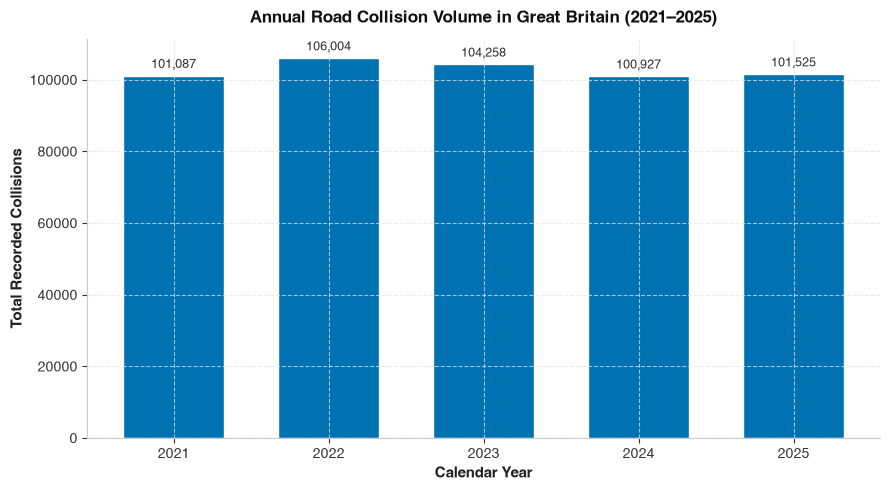

In [2]:
df_year = query_df("SELECT accident_year, total_collisions, severe_percentage FROM v_yearly_trend ORDER BY accident_year ASC;")
fig = plots.plot_bar(df_year, "accident_year", "total_collisions", "Annual Road Collision Volume in Great Britain (2021–2025)", "Calendar Year", "Total Recorded Collisions", color="#0072B2")
plt.show()


### 2. Seasonality and Monthly Variations

**Research Question**: What seasonal trends characterize road collisions across calendar months?

**What the Chart Shows**: Monthly aggregated collision volumes summed across 2021–2025.

**Key Insight**: Collisions reach seasonal lows in January and February (~34k–35k) and peak during late autumn (October/November ~46k–48k) as daylight hours decrease.

> [!NOTE]
> **Methodological Caveat**: Seasonal variations reflect a confluence of changing daylight, weather, and holiday travel volumes; association does not prove direct causation.


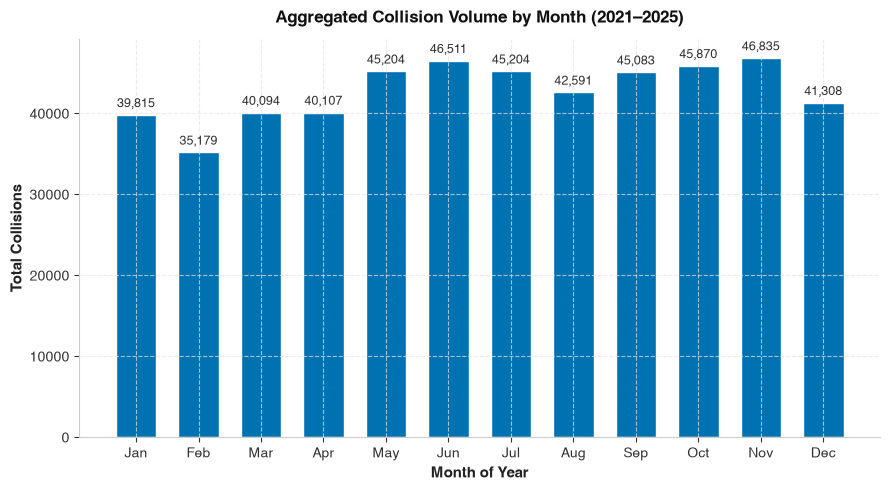

In [3]:
df_month = query_df("""
    SELECT 
        month,
        TO_CHAR(TO_DATE(month::TEXT, 'MM'), 'Mon') AS month_name,
        COUNT(*) AS total_collisions,
        ROUND(SUM(is_severe) * 100.0 / COUNT(*), 2) AS severe_percentage
    FROM v_accident_enriched
    WHERE month IS NOT NULL
    GROUP BY month
    ORDER BY month ASC;
""")
fig = plots.plot_bar(df_month, "month_name", "total_collisions", "Aggregated Collision Volume by Month (2021–2025)", "Month of Year", "Total Collisions", color="#0072B2")
plt.show()


### 3. Day of Week Collision Distribution

**Research Question**: How do collision counts vary between weekdays and weekends?

**What the Chart Shows**: Total collisions aggregated by day of the week.

**Key Insight**: Friday exhibits the highest collision count (85,311), while Sunday exhibits the lowest (57,781).

> [!NOTE]
> **Methodological Caveat**: Higher Friday volume reflects elevated rush hour and social travel; counts are unadjusted for daily traffic volumes.


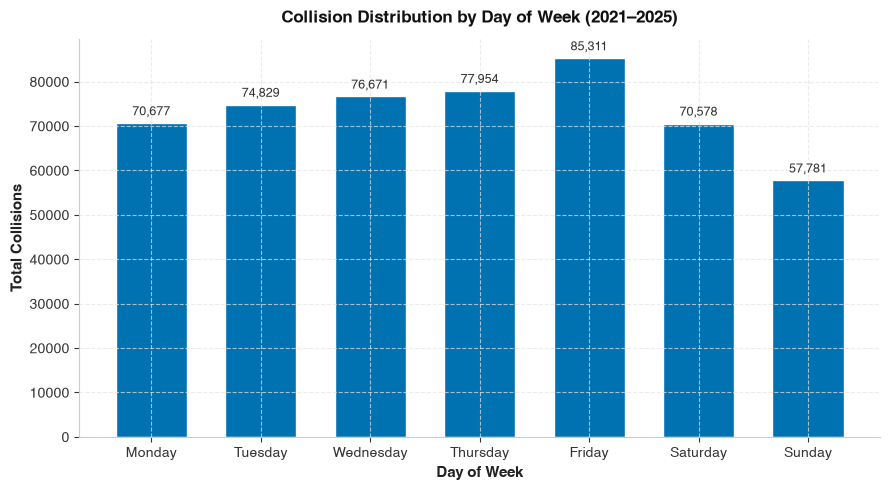

In [4]:
df_weekday = query_df("""
    SELECT 
        day_of_week_index,
        day_of_week_name,
        SUM(total_collisions) AS total_collisions
    FROM mv_hour_weekday_heatmap
    GROUP BY day_of_week_index, day_of_week_name
    ORDER BY day_of_week_index ASC;
""")
fig = plots.plot_bar(df_weekday, "day_of_week_name", "total_collisions", "Collision Distribution by Day of Week (2021–2025)", "Day of Week", "Total Collisions", color="#0072B2")
plt.show()


### 4. Diurnal Hourly Collision Profile

**Research Question**: At what hours of the day do most road traffic collisions occur?

**What the Chart Shows**: Line chart displaying total collisions by hour of day (0–23).

**Key Insight**: A bi-modal distribution emerges, with distinct morning peak (08:00, ~36k) and evening rush hour peak (17:00, ~46k).

> [!NOTE]
> **Methodological Caveat**: Peak hourly counts correspond with peak vehicle traffic on roads, not necessarily higher per-driver error rates.


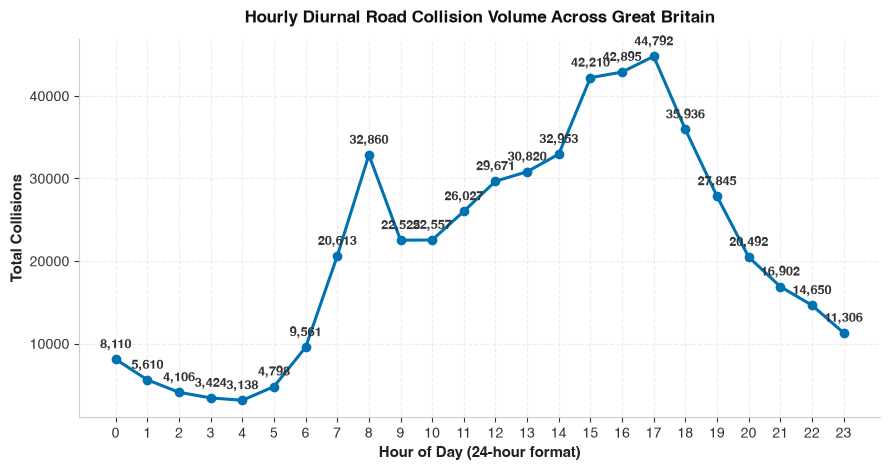

In [5]:
df_hour = query_df("""
    SELECT 
        hour,
        SUM(total_collisions) AS total_collisions
    FROM mv_hour_weekday_heatmap
    GROUP BY hour
    ORDER BY hour ASC;
""")
fig = plots.plot_line_trend(df_hour, "hour", "total_collisions", "Hourly Diurnal Road Collision Volume Across Great Britain", "Hour of Day (24-hour format)", "Total Collisions", color="#0072B2")
plt.show()


### 5. Weekday-by-Hour Heatmap Matrix

**Research Question**: What are the highest-risk temporal intervals when cross-tabulating day of week and hour of day?

**What the Chart Shows**: 7x24 heatmap displaying collision density across weekdays and hours.

**Key Insight**: Weekday commute hours (08:00–09:00 and 16:00–18:00 Monday–Friday) form intense hotspots, while weekend collisions disperse across afternoon hours.

> [!NOTE]
> **Methodological Caveat**: Materialized views cache these aggregates for fast querying; exposure data remains unobserved.


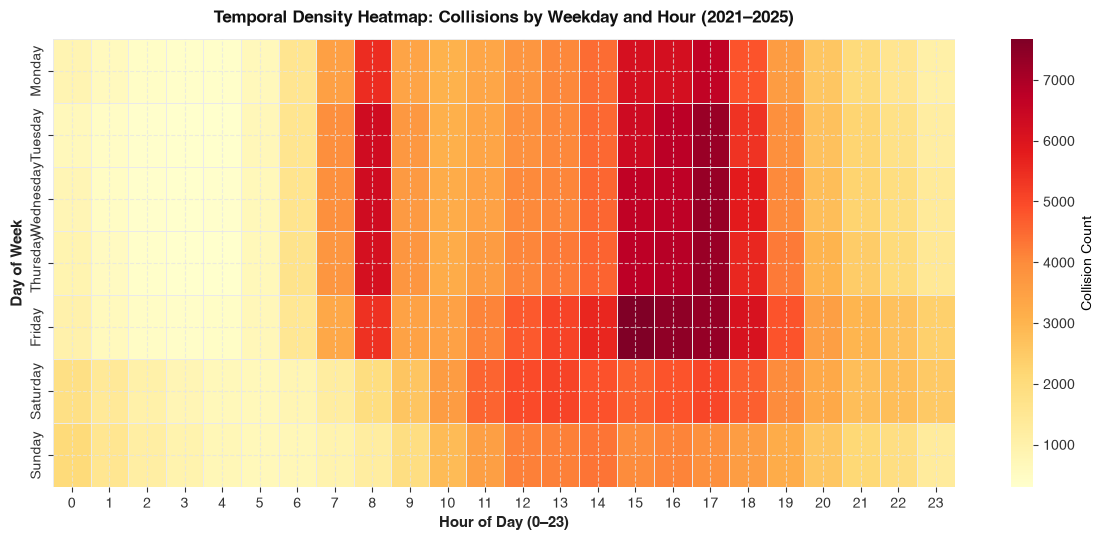

In [6]:
df_hm = query_df("SELECT day_of_week_name, hour, total_collisions FROM mv_hour_weekday_heatmap;")
fig = plots.plot_weekday_hour_heatmap(df_hm, "day_of_week_name", "hour", "total_collisions", "Temporal Density Heatmap: Collisions by Weekday and Hour (2021–2025)")
plt.show()


### 6. Collision Severity Class Distribution

**Research Question**: What is the breakdown of recorded road collisions by official STATS19 severity classification?

**What the Chart Shows**: Bar chart showing counts and shares for Fatal, Serious, and Slight collisions.

**Key Insight**: Slight collisions represent 75.8% (389,435), Serious collisions represent 22.7% (116,813), and Fatal collisions account for 1.5% (7,553).

> [!NOTE]
> **Methodological Caveat**: Severe classifications (Fatal + Serious = 24.2%) form the binary prediction target for Milestone 7 machine learning models.


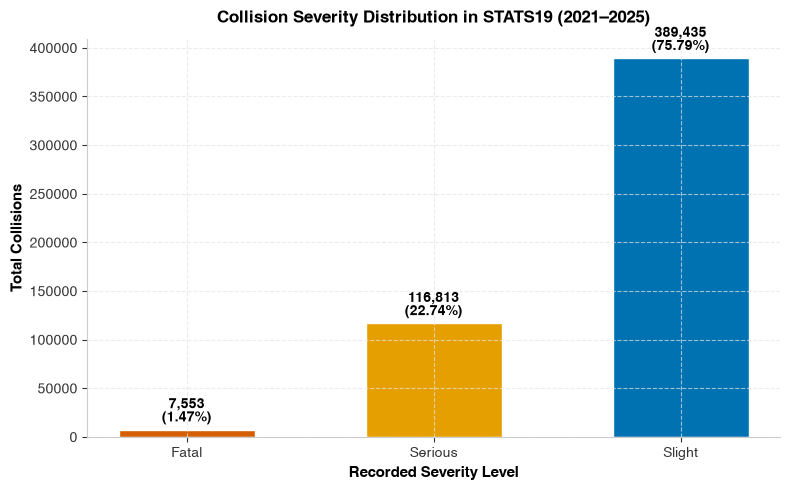

In [7]:
df_sev = query_df("""
    SELECT 
        s.severity_name,
        COUNT(*) AS total_collisions,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage
    FROM v_accident_enriched a
    JOIN severity s ON a.severity_id = s.severity_id
    GROUP BY s.severity_id, s.severity_name
    ORDER BY s.severity_id ASC;
""")
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#D55E00", "#E69F00", "#0072B2"]
bars = ax.bar(df_sev["severity_name"], df_sev["total_collisions"], color=colors, edgecolor="#FFFFFF", width=0.55)
for bar, pct in zip(bars, df_sev["percentage"]):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 5000, f"{h:,}\n({pct}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Collision Severity Distribution in STATS19 (2021–2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Total Collisions", fontsize=11, fontweight="bold")
ax.set_xlabel("Recorded Severity Level", fontsize=11, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


### 7. Hourly Severe Collision Percentage (with 95% Wilson CI)

**Research Question**: At what hours of the day are collisions most likely to be severe or fatal?

**What the Chart Shows**: Horizontal bar chart of severe collision rate per hour with 95% Wilson Score confidence interval error bars.

**Key Insight**: Between 00:00 and 04:00, severe crash percentages peak at ~30%–31%, compared to ~22%–24% during daytime hours.

> [!NOTE]
> **Methodological Caveat**: Higher nocturnal severity is influenced by higher travel speeds on empty roads and reduced visibility, not increased absolute crash counts.


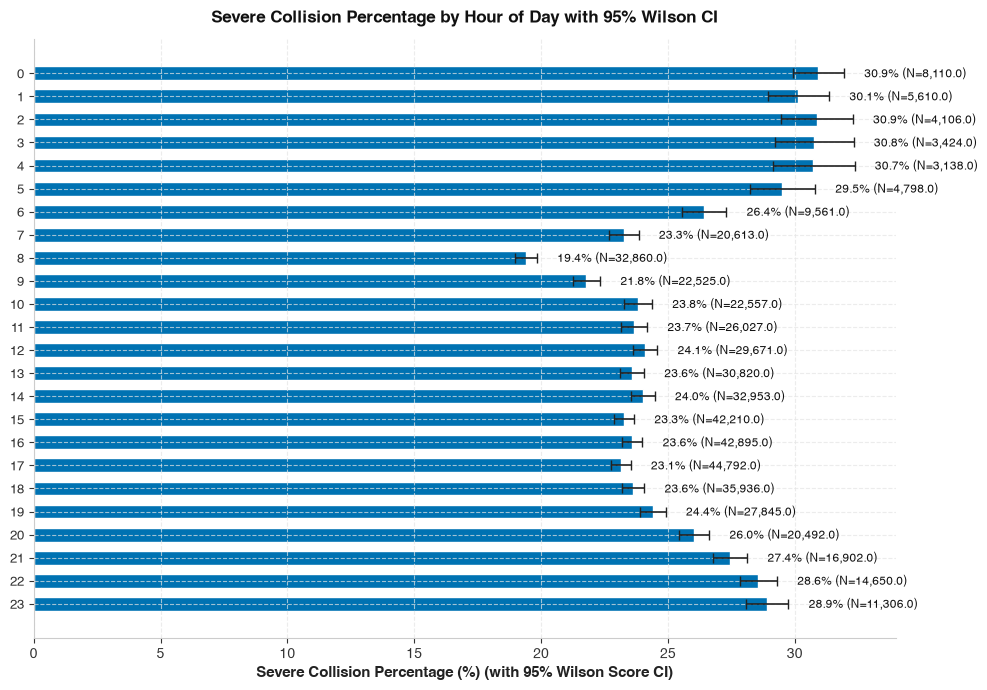

In [8]:
df_hsev = query_df("""
    SELECT 
        hour,
        SUM(total_collisions) AS total_count,
        SUM(severe_collisions) AS severe_count
    FROM mv_hour_weekday_heatmap
    GROUP BY hour
    ORDER BY hour ASC;
""")
fig = plots.plot_severity_rate_with_ci(df_hsev, "hour", "severe_count", "total_count", "Severe Collision Percentage by Hour of Day with 95% Wilson CI", "Severe Collision Percentage (%)", figsize=(10, 7))
plt.show()


### 8. Weather Conditions: Frequency vs Severity Rate

**Research Question**: How does atmospheric weather affect collision frequency and severity rate?

**What the Chart Shows**: Dual-axis chart displaying total collisions (bars, left) and severe percentage (line, right).

**Key Insight**: Fine weather accounts for 82.9% of collisions (24.7% severe), while fog/mist exhibits the highest severity rate (29.7%).

> [!NOTE]
> **Methodological Caveat**: The vast majority of collisions occur in fine weather because drivers travel vastly more miles in good weather (exposure bias).


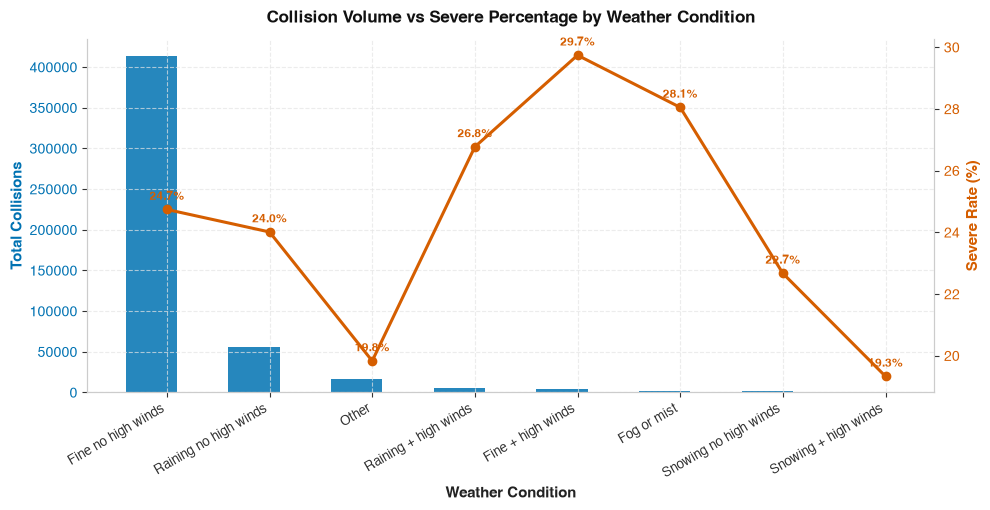

In [9]:
df_wea = query_df("""
    SELECT 
        weather_condition_name,
        COUNT(*) AS total_collisions,
        ROUND(SUM(is_severe) * 100.0 / COUNT(*), 2) AS severe_percentage
    FROM v_accident_enriched
    WHERE weather_condition_name != 'Unknown'
    GROUP BY weather_condition_name
    ORDER BY total_collisions DESC;
""")
fig = plots.plot_dual_axis_count_and_rate(df_wea, "weather_condition_name", "total_collisions", "severe_percentage", "Collision Volume vs Severe Percentage by Weather Condition", "Weather Condition", rotate_x=30)
plt.show()


### 9. Road Surface Condition Severe Rate (with 95% Wilson CI)

**Research Question**: What is the severe collision rate across dry, wet, and icy road surface conditions?

**What the Chart Shows**: Horizontal bar chart of severe crash rate by road surface with 95% Wilson Score CI.

**Key Insight**: Wet/damp roads have a 25.4% severe rate (N=120,572), while dry roads have 24.3% (N=374,268). Frost/ice has a slightly lower severe rate (22.7%) likely due to cautious, slower driving.

> [!NOTE]
> **Methodological Caveat**: Lower severity in icy conditions may reflect driver risk compensation (driving at lower speeds).


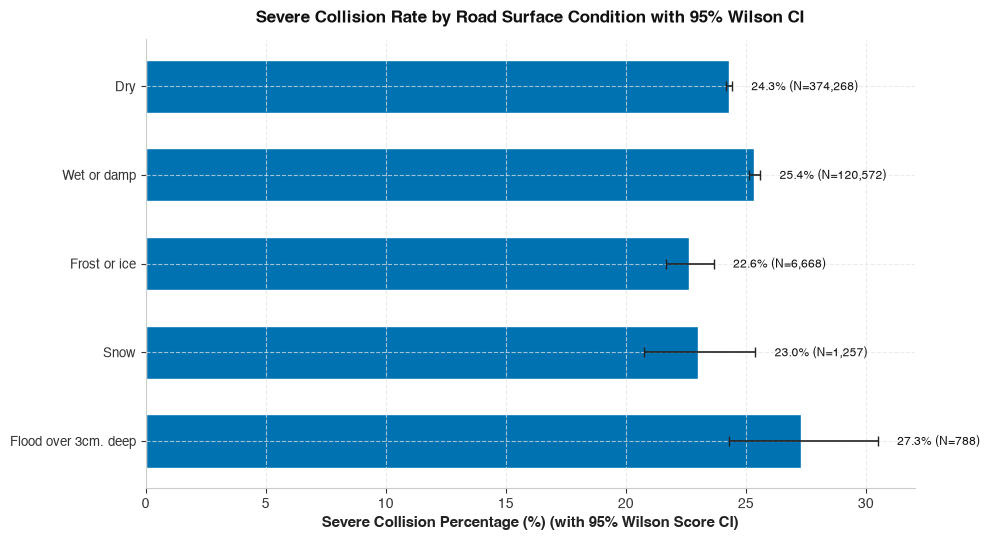

In [10]:
df_surf = query_df("""
    SELECT 
        road_surface_condition_name,
        SUM(is_severe) AS severe_count,
        COUNT(*) AS total_count
    FROM v_accident_enriched
    WHERE road_surface_condition_name != 'Unknown'
    GROUP BY road_surface_condition_name
    ORDER BY total_count DESC;
""")
fig = plots.plot_severity_rate_with_ci(df_surf, "road_surface_condition_name", "severe_count", "total_count", "Severe Collision Rate by Road Surface Condition with 95% Wilson CI", "Severe Collision Percentage (%)")
plt.show()


### 10. Ambient Light Condition Severe Rate (with 95% Wilson CI)

**Research Question**: How does ambient lighting influence the severity of road collisions?

**What the Chart Shows**: Horizontal bar chart of severe collision percentage across lighting conditions with 95% Wilson CI.

**Key Insight**: Darkness without street lighting exhibits a 31.9% severe collision rate, compared to 23.3% in daylight.

> [!NOTE]
> **Methodological Caveat**: Unlit darkness is heavily correlated with rural high-speed roads, confounding lighting with speed limit.


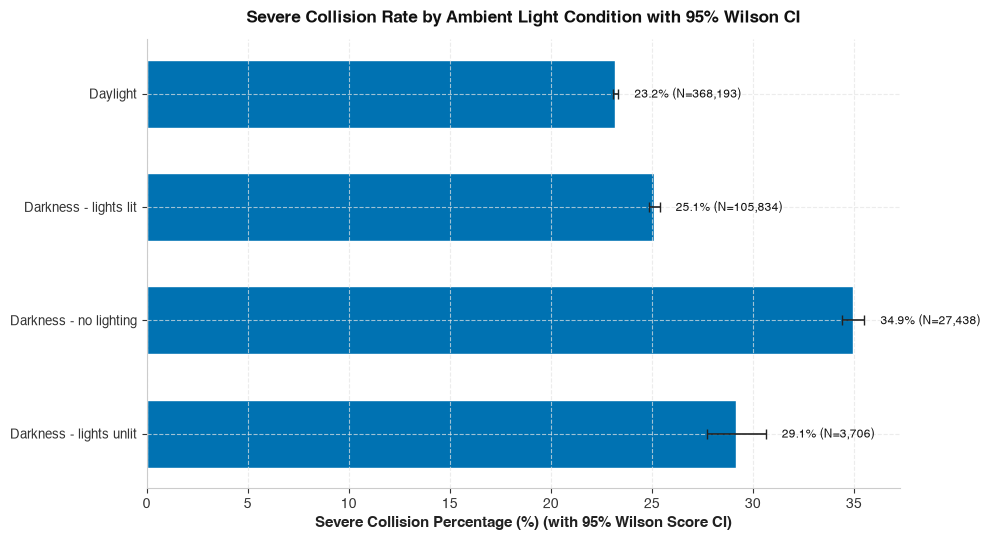

In [11]:
df_lgt = query_df("""
    SELECT 
        light_condition_name,
        SUM(is_severe) AS severe_count,
        COUNT(*) AS total_count
    FROM v_accident_enriched
    WHERE light_condition_name != 'Unknown'
    GROUP BY light_condition_name
    ORDER BY total_count DESC;
""")
fig = plots.plot_severity_rate_with_ci(df_lgt, "light_condition_name", "severe_count", "total_count", "Severe Collision Rate by Ambient Light Condition with 95% Wilson CI", "Severe Collision Percentage (%)")
plt.show()


### 11. Speed Limit Zones and Severity Outcomes

**Research Question**: How does the legal speed limit relate to the proportion of severe collisions?

**What the Chart Shows**: Severe collision rate across 20, 30, 40, 50, 60, and 70 mph speed zones with 95% Wilson CI.

**Key Insight**: Severe collision rate increases monotonically from 19.7% in 20 mph zones to 34.5% in 60 mph single-carriageway rural roads.

> [!NOTE]
> **Methodological Caveat**: 70 mph motorways show a dip to 24.6% because dual-carriageway barriers and lack of pedestrians reduce severe conflict points.


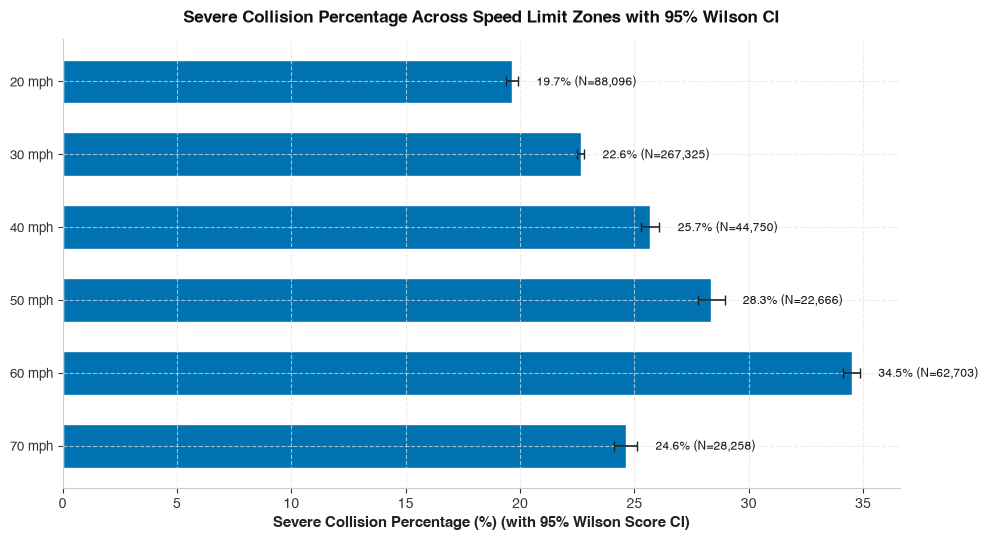

In [12]:
df_spd = query_df("""
    SELECT 
        speed_limit || ' mph' AS speed_label,
        SUM(is_severe) AS severe_count,
        COUNT(*) AS total_count
    FROM v_accident_enriched
    WHERE speed_limit IN (20, 30, 40, 50, 60, 70)
    GROUP BY speed_limit
    ORDER BY speed_limit ASC;
""")
fig = plots.plot_severity_rate_with_ci(df_spd, "speed_label", "severe_count", "total_count", "Severe Collision Percentage Across Speed Limit Zones with 95% Wilson CI", "Severe Collision Percentage (%)")
plt.show()


### 12. Road Type Severe Rate (with 95% Wilson CI)

**Research Question**: How does roadway layout (single carriageway, dual carriageway, roundabout, one way) impact severe crash rates?

**What the Chart Shows**: Severe crash percentage across roadway layouts with 95% Wilson CI.

**Key Insight**: Single carriageways account for 74% of collisions and have a 24.8% severe rate. Roundabouts have the lowest severe rate (17.5%) due to low-angle, low-speed merging impacts.

> [!NOTE]
> **Methodological Caveat**: Roundabouts prevent head-on collisions, substantially mitigating kinetic energy exchange.


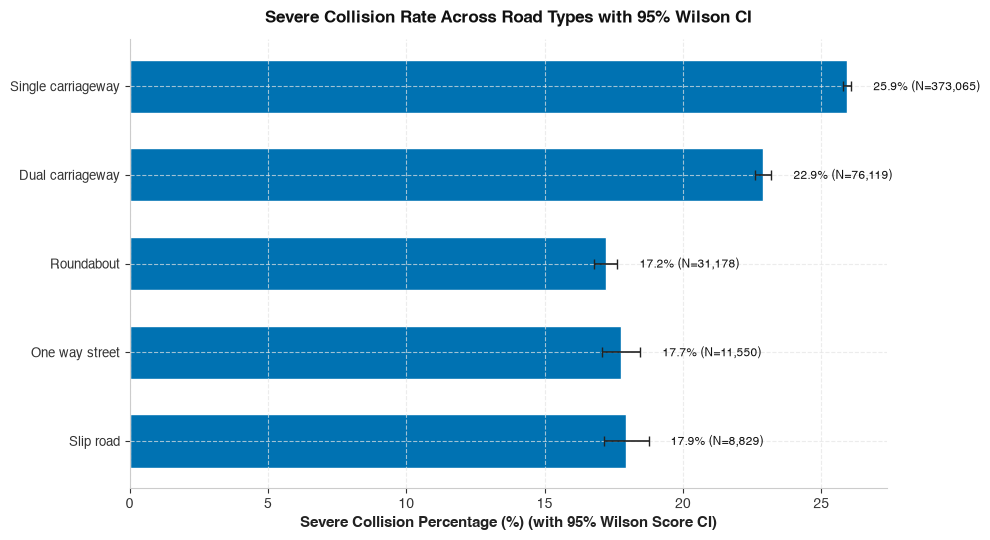

In [13]:
df_rt = query_df("""
    SELECT 
        road_type_name,
        SUM(is_severe) AS severe_count,
        COUNT(*) AS total_count
    FROM v_accident_enriched
    WHERE road_type_name != 'Unknown'
    GROUP BY road_type_name
    ORDER BY total_count DESC;
""")
fig = plots.plot_severity_rate_with_ci(df_rt, "road_type_name", "severe_count", "total_count", "Severe Collision Rate Across Road Types with 95% Wilson CI", "Severe Collision Percentage (%)")
plt.show()


### 13. Top 10 Vehicle Classifications Involved in Collisions

**Research Question**: Which vehicle categories are most frequently involved in traffic collisions across Great Britain?

**What the Chart Shows**: Horizontal bar chart of top 10 vehicle types recorded in collision files.

**Key Insight**: Passenger cars dominate (637,681 vehicles), followed by pedal cycles (81,486) and light commercial vans (60,309).

> [!NOTE]
> **Methodological Caveat**: Higher vehicle counts reflect national vehicle fleet proportions and mileage share.


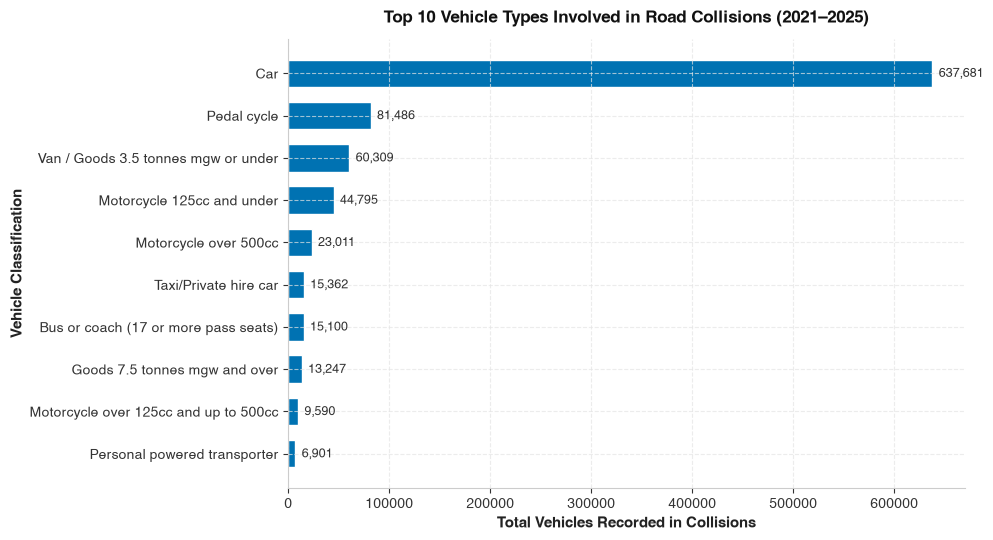

In [14]:
df_veh = query_df("""
    SELECT 
        vt.vehicle_type_name,
        COUNT(v.vehicle_id) AS total_vehicles
    FROM vehicle v
    JOIN vehicle_type vt ON v.vehicle_type_id = vt.vehicle_type_id
    GROUP BY vt.vehicle_type_id, vt.vehicle_type_name
    ORDER BY total_vehicles DESC
    LIMIT 10;
""")
fig = plots.plot_bar(df_veh, "total_vehicles", "vehicle_type_name", "Top 10 Vehicle Types Involved in Road Collisions (2021–2025)", "Total Vehicles Recorded in Collisions", "Vehicle Classification", horizontal=True, color="#0072B2", figsize=(10, 5.5))
plt.show()


### 14. Urban vs Rural Severity Comparison (with 95% Wilson CI)

**Research Question**: How does crash severity differ between urban and rural environments?

**What the Chart Shows**: Comparison of severe collision rates between urban and rural environments with 95% Wilson CI.

**Key Insight**: Rural collisions have a 29.4% severe rate (N=153,607), significantly higher than urban collisions at 21.9% (N=360,136).

> [!NOTE]
> **Methodological Caveat**: Rural collisions involve higher operating speeds, undivided roads, and longer ambulance travel times.


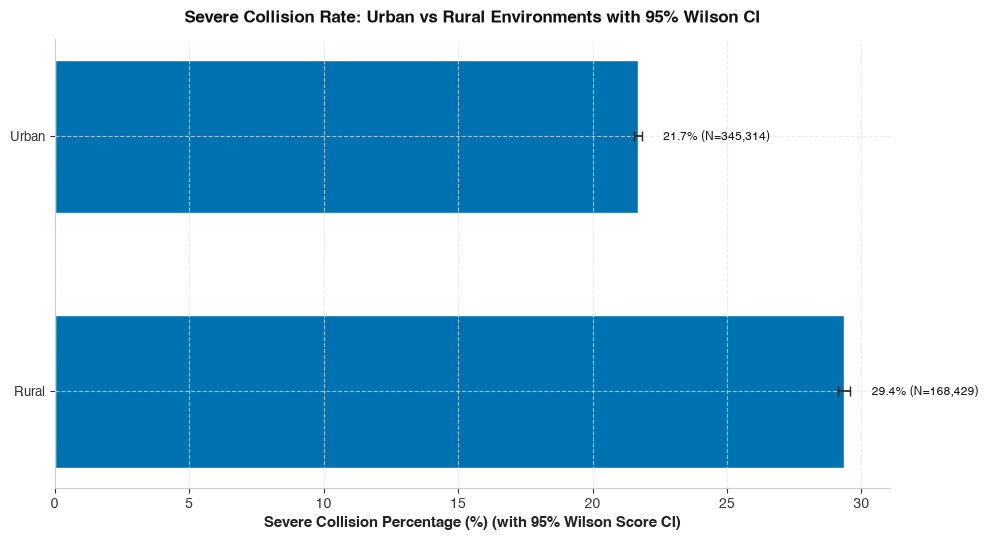

In [15]:
df_ur = query_df("""
    SELECT 
        urban_rural_name,
        SUM(is_severe) AS severe_count,
        COUNT(*) AS total_count
    FROM v_accident_enriched
    WHERE urban_rural_name != 'Unknown'
    GROUP BY urban_rural_name
    ORDER BY total_count DESC;
""")
fig = plots.plot_severity_rate_with_ci(df_ur, "urban_rural_name", "severe_count", "total_count", "Severe Collision Rate: Urban vs Rural Environments with 95% Wilson CI", "Severe Collision Percentage (%)")
plt.show()


### 15. Data Quality & Preprocessing Sentinel Missingness Overview

**Research Question**: Which raw STATS19 columns exhibited the highest missingness or domain sentinel values during preprocessing?

**What the Chart Shows**: Horizontal bar chart of top sentinel conversion counts from quality_report.json.

**Key Insight**: Legacy fields such as local_authority_district (513k converted) and junction_control (229k converted) had substantial unrecorded or sentinel entries.

> [!NOTE]
> **Methodological Caveat**: Converting sentinels (-1, 99) to SQL NULLs was essential in Milestone 2 to prevent mathematical skew.


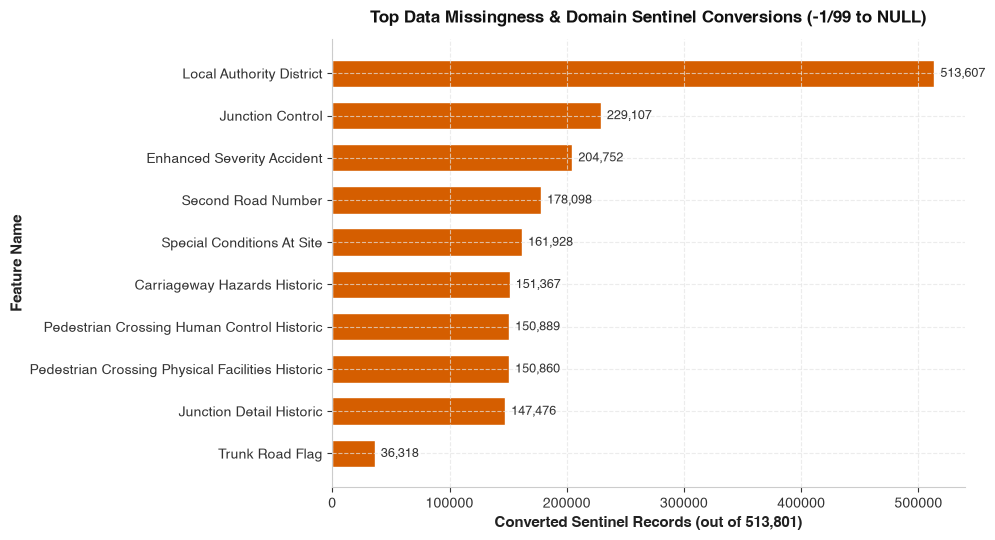

In [16]:
import json
qr_path = config.PROCESSED_DATA_DIR / "quality_report.json"
sentinels_data = []
if qr_path.exists():
    with open(qr_path, "r", encoding="utf-8") as f:
        qr = json.load(f)
    acc_sent = qr.get("cleaning_details", {}).get("accidents", {}).get("sentinels_converted", {})
    for col, count in sorted(acc_sent.items(), key=lambda x: x[1], reverse=True)[:10]:
        sentinels_data.append({"column_name": col.replace("_", " ").title(), "missing_count": count})
df_miss = pd.DataFrame(sentinels_data)
fig = plots.plot_bar(df_miss, "missing_count", "column_name", "Top Data Missingness & Domain Sentinel Conversions (-1/99 to NULL)", "Converted Sentinel Records (out of 513,801)", "Feature Name", horizontal=True, color="#D55E00", figsize=(10, 5.5))
plt.show()
